In [11]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torch.optim as optim

import torchvision.transforms as transforms

from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns


In [12]:
class AlzheimerDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform
        
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        img = Image.open(img_path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        label = self.labels[idx]
        return img, label


In [13]:
root = "C:/Users/sanja/Desktop/MRI_Project/AD_DATASET/Processed_Final"   # update your path

categories = ["Non_Demented", "Mild_Dementia", "Moderate_Dementia", "Very_mild_Dementia"]

image_paths = []
labels = []

for label, folder in enumerate(categories):
    folder_path = os.path.join(root, folder)
    for file in os.listdir(folder_path):
        image_paths.append(os.path.join(folder_path, file))
        labels.append(label)

labels = np.array(labels)


In [14]:
train_paths, test_paths, train_labels, test_labels = train_test_split(
    image_paths, labels, test_size=0.2, random_state=42, stratify=labels
)


In [15]:
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])


In [16]:
class_counts = np.bincount(train_labels)
class_weights = 1.0 / class_counts
sample_weights = class_weights[train_labels]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)


In [17]:
train_dataset = AlzheimerDataset(train_paths, train_labels, transform=train_transform)
test_dataset  = AlzheimerDataset(test_paths, test_labels, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=32, sampler=sampler)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)


In [18]:
class AlzheimerCNN(nn.Module):
    def __init__(self):
        super(AlzheimerCNN, self).__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=2, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.25),

            nn.Conv2d(32, 64, kernel_size=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=2, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.25),

            nn.Conv2d(64, 128, kernel_size=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=2, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(2, 2),
            nn.Dropout(0.25),
        )

        # compute final feature count dynamically
        self._to_linear = None
        self._get_flattened_size()

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self._to_linear, 256),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(256, 4)
        )

    def _get_flattened_size(self):
        x = torch.randn(1, 3, 128, 128)  # sample input
        x = self.conv_layers(x)
        self._to_linear = x.numel()

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = AlzheimerCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)


In [20]:
num_epochs = 10
train_acc_hist = []
train_loss_hist = []
val_acc_hist = []
val_loss_hist = []

for epoch in range(num_epochs):

    model.train()
    correct = 0
    total = 0
    running_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    train_loss = running_loss / len(train_loader)
    train_acc = correct / total

    # Validation
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)

            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= len(test_loader)
    val_acc = val_correct / val_total

    train_loss_hist.append(train_loss)
    train_acc_hist.append(train_acc)
    val_loss_hist.append(val_loss)
    val_acc_hist.append(val_acc)

    print(f"Epoch {epoch+1}/{num_epochs} - Train Acc: {train_acc:.4f} - Val Acc: {val_acc:.4f}")


Epoch 1/10 - Train Acc: 0.7464 - Val Acc: 0.8691
Epoch 2/10 - Train Acc: 0.8782 - Val Acc: 0.9287
Epoch 3/10 - Train Acc: 0.9134 - Val Acc: 0.9519
Epoch 4/10 - Train Acc: 0.9308 - Val Acc: 0.9605
Epoch 5/10 - Train Acc: 0.9445 - Val Acc: 0.9774
Epoch 6/10 - Train Acc: 0.9510 - Val Acc: 0.9436
Epoch 7/10 - Train Acc: 0.9579 - Val Acc: 0.9712
Epoch 8/10 - Train Acc: 0.9621 - Val Acc: 0.9772
Epoch 9/10 - Train Acc: 0.9650 - Val Acc: 0.9731
Epoch 10/10 - Train Acc: 0.9682 - Val Acc: 0.9794


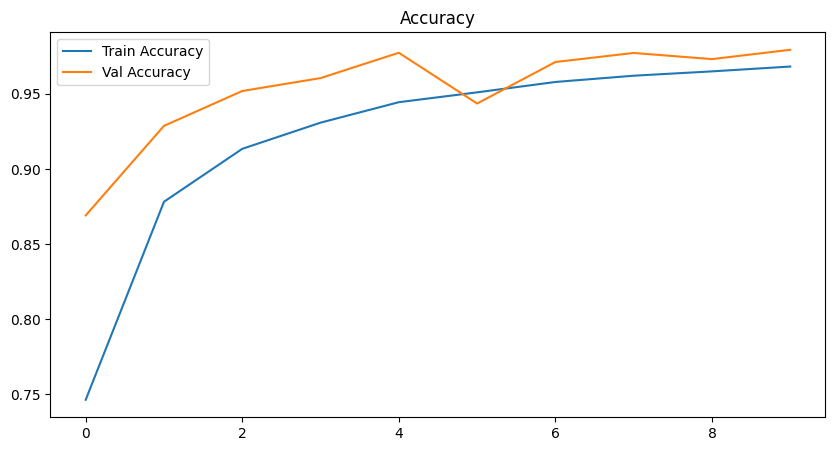

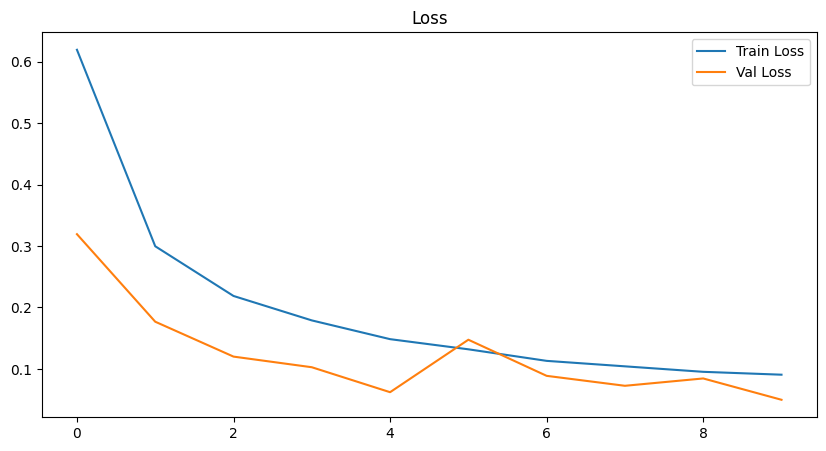

In [21]:
plt.figure(figsize=(10,5))
plt.plot(train_acc_hist, label="Train Accuracy")
plt.plot(val_acc_hist, label="Val Accuracy")
plt.legend(); plt.title("Accuracy"); plt.show()

plt.figure(figsize=(10,5))
plt.plot(train_loss_hist, label="Train Loss")
plt.plot(val_loss_hist, label="Val Loss")
plt.legend(); plt.title("Loss"); plt.show()


In [22]:
model.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)

        probs = torch.softmax(outputs, dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)

        all_probs.extend(probs)
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())


In [23]:
print(classification_report(all_labels, all_preds, target_names=categories))


                    precision    recall  f1-score   support

      Non_Demented       1.00      0.97      0.98      8000
     Mild_Dementia       0.97      0.99      0.98      2000
 Moderate_Dementia       1.00      1.00      1.00      1600
Very_mild_Dementia       0.94      0.99      0.96      4000

          accuracy                           0.98     15600
         macro avg       0.98      0.99      0.98     15600
      weighted avg       0.98      0.98      0.98     15600



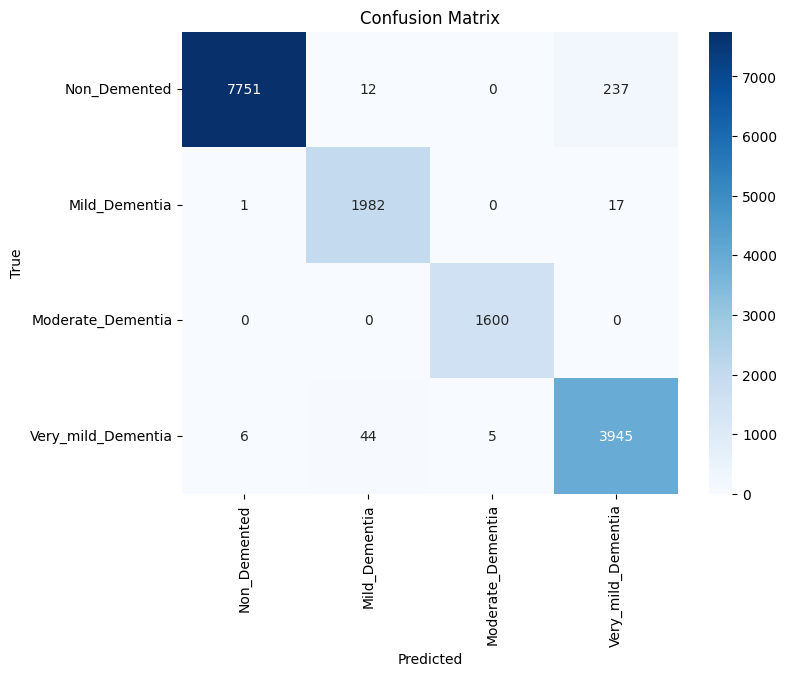

In [24]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=categories, yticklabels=categories)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


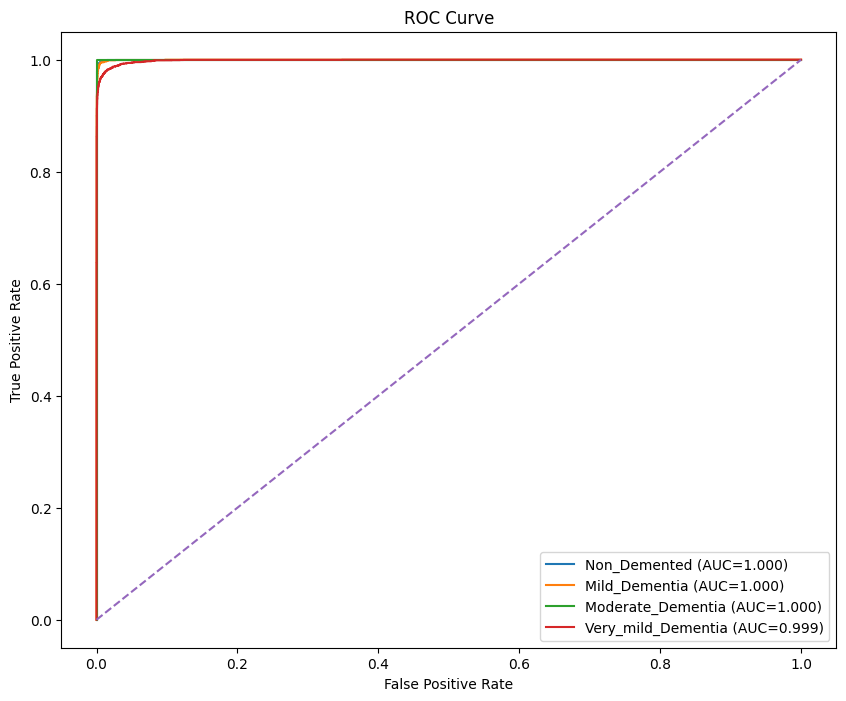

In [25]:
from sklearn.preprocessing import label_binarize

y_test_bin = label_binarize(all_labels, classes=[0,1,2,3])
all_probs = np.array(all_probs)

plt.figure(figsize=(10,8))

for i in range(4):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], all_probs[:, i])
    auc_score = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{categories[i]} (AUC={auc_score:.3f})")

plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
